<a href="https://colab.research.google.com/github/natenorris10/MAT-422/blob/main/HW_3_5_and_3_6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Calculus and Optimization - 3.5, 3.6

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import make_blobs, make_classification
from sklearn.cluster import KMeans
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

###3.5 - K-means

K-means clustering is a method that involves grouping data into k clusters.  The idea is to choose k numbers of groups, and each observation will belong in whatever group has the shortest distance to the group's center, or in other words, the cluster's mean.

Cluster Centers: 
 [[ 2.82333177  4.93942442]
 [ 5.5037613  -9.5861544 ]
 [-5.87619982  5.1449    ]
 [-0.01216789 -5.50915831]]
Inertia:  228.72280176067588


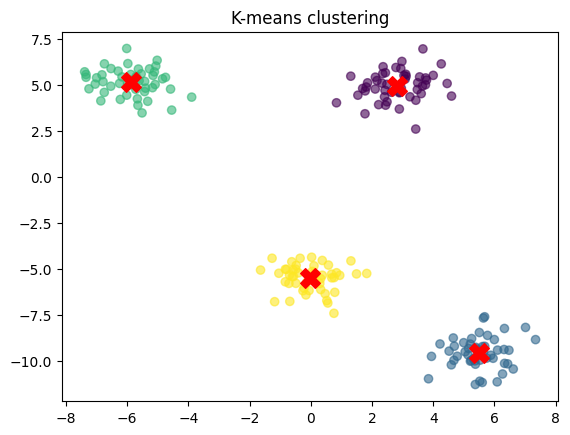

In [ ]:
X, true_labels = make_blobs(n_samples=200, centers=4, cluster_std=0.8,
                            random_state=10)
kmeans = KMeans(n_clusters=4, n_init="auto", random_state=10)
cluster_labels = kmeans.fit_predict(X)

print("Cluster Centers: \n", kmeans.cluster_centers_)
print("Inertia: ", kmeans.inertia_)

plt.scatter(X[:,0], X[:,1], c=cluster_labels, cmap="viridis", alpha=0.6)
plt.scatter(kmeans.cluster_centers_[:,0], kmeans.cluster_centers_[:,1],
            marker="X", s=200, color="red")
plt.title("K-means clustering")
plt.show()

###3.6 - Support Vector Machines

Support Vector Machines are a collection of learning algorithms for regression and classification.  The goal is to find a hyperplane of the number of features in a high-dimensional space that helps classify the data points.  A SVM will map training points such that they're split into categories, maximizing the gap between them.  Then, depending on what side of the gap new data points fall on will determine their classification.

Training accuracy:  0.875
Number of support vectors:  [30 30]


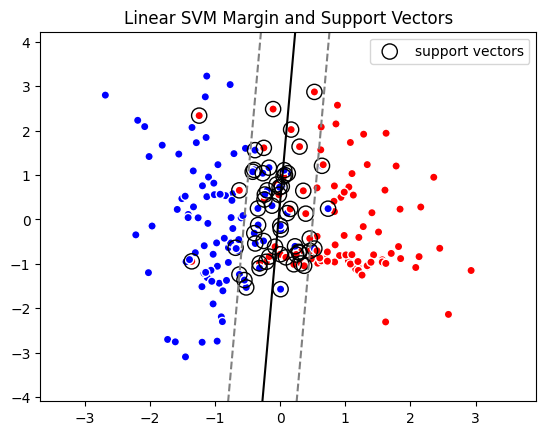

In [8]:
Xc, yc = make_classification(n_samples=200, n_features=2, n_informative=2,
                             n_redundant=0, n_clusters_per_class=2,
                             class_sep=0.9, random_state=10)
svm = SVC(kernel="linear", C=1.0)
svm.fit(Xc, yc)
pred = svm.predict(Xc)

print("Training accuracy: ", accuracy_score(yc, pred))
print("Number of support vectors: ", svm.n_support_)

xx, yy = np.meshgrid(np.linspace(Xc[:,0].min()-1, Xc[:,0].max()+1, 150),
                     np.linspace(Xc[:,1].min()-1, Xc[:,1].max()+1, 150))
Z = svm.decision_function(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

plt.contour(xx, yy, Z, levels=[-1, 0, 1], colors=["gray", "black", "gray"],
            linestyles=["--", "-", "--"])
plt.scatter(Xc[:,0], Xc[:,1], c=yc, cmap="bwr", edgecolor="white")
plt.scatter(svm.support_vectors_[:,0], svm.support_vectors_[:,1], s=120,
            facecolors="none", edgecolors="black", label="support vectors")
plt.title("Linear SVM Margin and Support Vectors")
plt.legend()
plt.show()